In [1]:
import numpy as np
from scipy.optimize import differential_evolution
import matplotlib.pyplot as plt
from time import time
from itertools import product
from matplotlib.colors import Normalize
import matplotlib.cm as cm

In [2]:
def vec_real_pos_roots(array_of_coeffs):
    num_eqs = array_of_coeffs.shape[0]
    max_real_pos_roots_list = []
    for eq in range(num_eqs):
        coeffs = array_of_coeffs[eq,:]
        cubic_roots = np.polynomial.polynomial.Polynomial(coeffs).roots()
        real_roots_bool = np.isreal(cubic_roots)
        real_roots = np.real(cubic_roots[real_roots_bool])
        real_pos_roots = np.where(real_roots > 0, real_roots, 0)
        max_real_pos_root = np.max(real_pos_roots)
        max_real_pos_roots_list.append(max_real_pos_root)
    max_real_pos_roots_array = np.array(max_real_pos_roots_list)
    return max_real_pos_roots_array
    
def spec_site_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con, del_e_con):
    '''
    Function that calculates the occupancy of specific sites as the number of specific sites bound by a TF divided by the total number of'
    specific sites. Specific sites contain the motif and are in a target promoter. Competitor sites contain the motif but are not in
    a target promoter (AKA motif in the wrong location). Nonspecific sites are just available DNA (don't contain the motif and wrong
    location). This ratio is calculated using a grand canonical ensemble MWC model.

    Parameters
    ----------
    n_s : int
        number of specific sites (motif occurences in target promoters, lower B-to-A energy)
    n_c : int
        number of competitor sites (motif occurences outside of target promoters)
    n_ns : int
        number of nonspecific sites (availble DNA that is not specific nor competitor sites)
    T : int
        number of TFs in the nucleus
    e_bind_s_c_a : int or float
        Binding energy for the TF to bind specific or competitor sites. Because competitor sites have the motif and can be A-DNA or B-DNA,
        they have the same binding energy as specific sites. 
    e_con: int or float
        Conformational energy difference for a site type; differenence in conformation energy for a sequence to go from B-DNA to A-DNA.
    del_e_con : int or float
        Parameter representing the conformational energy difference between sites. Because specific sites have flank sequences with greater
        A-DNA dinucleotide content, we assume that these sites have an easier time (lower e_con) going from B-DNA to A-DNA compared to
        competitor and nonspecific sites.

    Returns
    -------
    ratio : float
        Ratio of specifically bound TFs to TFs bound at either competitor or nonspecific sites
    '''
    
    # define the specific site binding energies. Competitor sites have the same binding energy, so we will reuse these binding energies
    # for those sites as well
    e_bind_s_c_b = e_bind_s_c_a + np.log(10)
    
    # define binding energies for nonspeicfic sites
    e_bind_ns_b = e_bind_s_c_a + np.log(50)
    e_bind_ns_a = e_bind_s_c_a + np.log(10)

    # define variable represeting exponential MWC energies 
    # x for the the binding energies
    x_s_c_b = np.exp(-e_bind_s_c_b)
    x_s_c_a = np.exp(-e_bind_s_c_a)
    x_ns_b = np.exp(-e_bind_ns_b)
    x_ns_a = np.exp(-e_bind_ns_a)
    # y for conformation energies
    y_s = np.exp(-e_con - del_e_con)
    y_c_ns = np.exp(-e_con)

    # define variables to represent the weight of bound states from the binding energies
    alpha_s = x_s_c_b + x_s_c_a * y_s
    alpha_c = x_s_c_b + x_s_c_a * y_c_ns
    alpha_ns = x_ns_b + x_ns_a * y_c_ns
    
    # define the fugacity as a function of the parameters and variables define so far
    a = alpha_s * alpha_c * alpha_ns * (n_s + n_c + n_ns - T)
    b1 = (1+y_s) * alpha_c * alpha_ns * (n_c + n_ns - T)
    b2 = (1+y_c_ns) * alpha_s * alpha_ns * (n_s + n_ns - T)
    b3 = (1+y_c_ns) * alpha_s * alpha_c * (n_s + n_c - T)
    b = b1 + b2 + b3
    c1 = (n_s - T) * alpha_s * (1 + y_c_ns) * (1 + y_c_ns)
    c2 = (n_c - T) * alpha_c * (1 + y_s) * (1 + y_c_ns)
    c3 = (n_ns - T) * alpha_ns * (1 + y_s) * (1+ y_c_ns)
    c = c1 + c2 + c3
    d = -T * (1 + y_c_ns) * (1 + y_s) * (1 + y_c_ns) 
    if type(a) == np.ndarray:
        coeff_array = np.vstack([d,c,b,a]).T
    else:
        coeff_array = np.array([[d,c,b,a]])
    fugacity = vec_real_pos_roots(coeff_array)

    # define the partition functions for specific, competitor, and nonspecific sites
    q_s = 1 + y_s + fugacity * alpha_s
    q_c = 1 + y_c_ns + fugacity * alpha_c
    q_ns  = 1 + y_c_ns + fugacity * alpha_ns

    # define the occupation probabilities of each site
    p_s =  (fugacity * alpha_s) / q_s
    p_c =  (fugacity * alpha_c) / q_c
    p_ns =  (fugacity * alpha_ns) / q_ns

    # define the number of TFs bound to each site
    bound_s = p_s * n_s
    bound_c = p_c * n_c
    bound_ns = p_ns * n_ns

    # calculate ratio
    occupancy = bound_s / n_s

    return occupancy

def spec_site_dbd_occupancy(n_s, n_c, n_ns, T, e_bind_s_c):
    '''
    Function that calculates the occupancy of specific sites as the number of specific sites bound by a DBD divided by the total number 
    of specific sites. Specific sites contain the motif and are in a target promoter. Competitor sites contain the motif but are not in
    a target promoter (AKA motif in the wrong location). Nonspecific sites are just available DNA (don't contain the motif and wrong
    location). This ratio is calculated using a grand canonical ensemble MWC model.

    Parameters
    ----------
    n_s : int
        number of specific sites (motif occurences in target promoters, lower B-to-A energy)
    n_c : int
        number of competitor sites (motif occurences outside of target promoters)
    n_ns : int
        number of nonspecific sites (availble DNA that is not specific nor competitor sites)
    T : int
        number of TFs in the nucleus
    e_bind_s_c_a : int or float
        Binding energy for the DBD to bind specific or competitor sites. Because competitor sites have the motif and can be A-DNA or B-DNA,
        they have the same binding energy as specific sites. 
        
    Returns
    -------
    occupancy : float
        Probability of any specific sites being occupied.
    '''
    
    # Specific and competitior sites have the same binding energy, so we will just use the same term for them
    
    # define binding energies for nonspeicfic sites
    e_bind_ns = e_bind_s_c + np.log(10)

    # define variable represeting exponential MWC energies 
    # x for the the binding energies
    x_s_c = np.exp(-e_bind_s_c)
    x_ns = np.exp(-e_bind_ns)
    
    # define the fugacity as a function of the parameters and variables define so far
    a = x_s_c * x_s_c * x_ns * (n_s + n_c + n_ns - T)
    b1 = x_s_c * x_s_c * (n_s + n_c - T)
    b2 = x_s_c * x_ns * (n_c + n_ns - T)
    b3 = x_s_c * x_ns * (n_c + n_ns - T)
    b = b1 + b2 + b3
    c1 = x_s_c * (n_s - T)
    c2 = x_s_c * (n_c - T)
    c3 = x_ns * (n_ns - T)
    c = c1 + c2 + c3
    d = -T 
    if type(a) == np.ndarray:
        coeff_array = np.vstack([d,c,b,a]).T
    else:
        coeff_array = np.array([[d,c,b,a]])
    fugacity = vec_real_pos_roots(coeff_array)

    # define the partition functions for specific, competitor, and nonspecific sites
    q_s = 1 + fugacity * x_s_c
    q_c = 1 + fugacity * x_s_c
    q_ns  = 1 + fugacity * x_ns

    # define the occupation probabilities of each site
    p_s =  (fugacity * x_s_c) / q_s
    p_c =  (fugacity * x_s_c) / q_c
    p_ns =  (fugacity * x_ns) / q_ns

    # define the number of TFs bound to each site
    bound_s = p_s * n_s
    bound_c = p_c * n_c
    bound_ns = p_ns * n_ns

    # calculate ratio
    occupancy = bound_s / n_s

    return occupancy

def null_occupancy(n_s, n_c, n_ns, T, e_bind, e_con = 0, del_e_con = 0):
    '''
    Function that calculates the occupancy of specific sites as the number of specific sites bound by a TF divided by the total number of'
    specific sites. However, unlike previous models, all the sites are identical. This function is used to cacluate reference probabilities
    to get a sense of how much specificity is conferred by the TF having a preferred motif and / or the TF having a preference for a certain
    DNA conformation

    Parameters
    ----------
    n_s : int
        number of specific sites (motif occurences in target promoters, lower B-to-A energy)
    n_c : int
        number of competitor sites (motif occurences outside of target promoters)
    n_ns : int
        number of nonspecific sites (availble DNA that is not specific nor competitor sites)
    T : int
        number of TFs in the nucleus
    e_bind_ : int or float
        Binding energy for the TF to bind any site. 
    e_con: int or float
        Conformational energy difference for a site type; differenence in conformation energy for a sequence to go from B-DNA to A-DNA.
    del_e_con : int or float
        Parameter representing the conformational energy difference between sites. Because specific sites have flank sequences with greater
        A-DNA dinucleotide content, we assume that these sites have an easier time (lower e_con) going from B-DNA to A-DNA compared to
        competitor and nonspecific sites.

    Returns
    -------
    ratio : float
        Ratio of specifically bound TFs to TFs bound at either competitor or nonspecific sites
    '''
    
    # define the specific site binding energies. Competitor sites have the same binding energy, so we will reuse these binding energies
    # for those sites as well
    e_bind_s_c_a = e_bind
    e_bind_s_c_b = e_bind 
    
    # define binding energies for nonspeicfic sites
    e_bind_ns_b = e_bind 
    e_bind_ns_a = e_bind 

    # define variable represeting exponential MWC energies 
    # x for the the binding energies
    x_s_c_b = np.exp(-e_bind_s_c_b)
    x_s_c_a = np.exp(-e_bind_s_c_a)
    x_ns_b = np.exp(-e_bind_ns_b)
    x_ns_a = np.exp(-e_bind_ns_a)
    # y for conformation energies
    y_s = np.exp(-e_con - del_e_con)
    y_c_ns = np.exp(-e_con)

    # define variables to represent the weight of bound states from the binding energies
    alpha_s = x_s_c_b + x_s_c_a * y_s
    alpha_c = x_s_c_b + x_s_c_a * y_c_ns
    alpha_ns = x_ns_b + x_ns_a * y_c_ns
    
    # define the fugacity as a function of the parameters and variables define so far
    a = alpha_s * alpha_c * alpha_ns * (n_s + n_c + n_ns - T)
    b1 = (1+y_s) * alpha_c * alpha_ns * (n_c + n_ns - T)
    b2 = (1+y_c_ns) * alpha_s * alpha_ns * (n_s + n_ns - T)
    b3 = (1+y_c_ns) * alpha_s * alpha_c * (n_s + n_c - T)
    b = b1 + b2 + b3
    c1 = (n_s - T) * alpha_s * (1 + y_c_ns) * (1 + y_c_ns)
    c2 = (n_c - T) * alpha_c * (1 + y_s) * (1 + y_c_ns)
    c3 = (n_ns - T) * alpha_ns * (1 + y_s) * (1+ y_c_ns)
    c = c1 + c2 + c3
    d = -T * (1 + y_c_ns) * (1 + y_s) * (1 + y_c_ns) 
    if type(a) == np.ndarray:
        coeff_array = np.vstack([d,c,b,a]).T
    else:
        coeff_array = np.array([[d,c,b,a]])
    fugacity = vec_real_pos_roots(coeff_array)

    # define the partition functions for specific, competitor, and nonspecific sites
    q_s = 1 + y_s + fugacity * alpha_s
    q_c = 1 + y_c_ns + fugacity * alpha_c
    q_ns  = 1 + y_c_ns + fugacity * alpha_ns

    # define the occupation probabilities of each site
    p_s =  (fugacity * alpha_s) / q_s
    p_c =  (fugacity * alpha_c) / q_c
    p_ns =  (fugacity * alpha_ns) / q_ns

    # define the number of TFs bound to each site
    bound_s = p_s * n_s
    bound_c = p_c * n_c
    bound_ns = p_ns * n_ns

    # calculate ratio
    occupancy = bound_s / n_s

    return occupancy

def fugacity_calc(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con, del_e_con):
    '''
    Function that calculates the fugacity parameter from the MWC model.

    Parameters
    ----------
    n_s : int
        number of specific sites (motif occurences in target promoters, lower B-to-A energy)
    n_c : int
        number of competitor sites (motif occurences outside of target promoters)
    n_ns : int
        number of nonspecific sites (availble DNA that is not specific nor competitor sites)
    T : int
        number of TFs in the nucleus
    e_bind_s_c_a : int or float
        Binding energy for the TF to bind specific or competitor sites. Because competitor sites have the motif and can be A-DNA or B-DNA,
        they have the same binding energy as specific sites. 
    e_con: int or float
        Conformational energy difference for a site type; differenence in conformation energy for a sequence to go from B-DNA to A-DNA.
    del_e_con : int or float
        Parameter representing the conformational energy difference between sites. Because specific sites have flank sequences with greater
        A-DNA dinucleotide content, we assume that these sites have an easier time (lower e_con) going from B-DNA to A-DNA compared to
        competitor and nonspecific sites.

    Returns
    -------
    ratio : float
        Ratio of specifically bound TFs to TFs bound at either competitor or nonspecific sites
    '''
    
    # define the specific site binding energies. Competitor sites have the same binding energy, so we will reuse these binding energies
    # for those sites as well
    e_bind_s_c_b = e_bind_s_c_a + np.log(10)
    
    # define binding energies for nonspeicfic sites
    e_bind_ns_b = e_bind_s_c_a + np.log(50)
    e_bind_ns_a = e_bind_s_c_a + np.log(5)

    # define variable represeting exponential MWC energies 
    # x for the the binding energies
    x_s_c_b = np.exp(-e_bind_s_c_b)
    x_s_c_a = np.exp(-e_bind_s_c_a)
    x_ns_b = np.exp(-e_bind_ns_b)
    x_ns_a = np.exp(-e_bind_ns_a)
    # y for conformation energies
    y_s = np.exp(-e_con - del_e_con)
    y_c_ns = np.exp(-e_con)

    # define variables to represent the weight of bound states from the binding energies
    alpha_s = x_s_c_b + x_s_c_a * y_s
    alpha_c = x_s_c_b + x_s_c_a * y_c_ns
    alpha_ns = x_ns_b + x_ns_a * y_c_ns
    
    # define the fugacity as a function of the parameters and variables define so far
    a = alpha_s * alpha_c * alpha_ns * (n_s + n_c + n_ns - T)
    b1 = (1+y_s) * alpha_c * alpha_ns * (n_c + n_ns - T)
    b2 = (1+y_c_ns) * alpha_s * alpha_ns * (n_s + n_ns - T)
    b3 = (1+y_c_ns) * alpha_s * alpha_c * (n_s + n_c - T)
    b = b1 + b2 + b3
    c1 = (n_s - T) * alpha_s * (1 + y_c_ns) * (1 + y_c_ns)
    c2 = (n_c - T) * alpha_c * (1 + y_s) * (1 + y_c_ns)
    c3 = (n_ns - T) * alpha_ns * (1 + y_s) * (1+ y_c_ns)
    c = c1 + c2 + c3
    d = -T * (1 + y_c_ns) * (1 + y_s) * (1 + y_c_ns) 
    if type(a) == np.ndarray:
        coeff_array = np.vstack([d,c,b,a]).T
    else:
        coeff_array = np.array([[d,c,b,a]])
    fugacity = vec_real_pos_roots(coeff_array)

    return fugacity

def spec_site_occupancy_if(n_s, n_c, n_ns, T, e_bind_s_a, e_con):
    '''
    Function that calculates the occupancy of specific sites as the number of specific sites bound by a TF divided by the total number of'
    specific sites. Specific sites contain the motif and are in a target promoter. Competitor sites contain the motif but are not in
    a target promoter (AKA motif in the wrong location). Nonspecific sites are just available DNA (don't contain the motif and wrong
    location). This ratio is calculated using a grand canonical ensemble MWC model. The _if indicates this is an induced fit model where
    only specific sites bind in the A-DNA conformation and the other sites bind in the B-DNA conformation. This model makes a hard 
    assumption that A-DNA states are only accessible to specific sites due to their lower conformation enegy. Thus, unlike the other
    models where there is a specific, competitor, and nonspecific conformation energies, the induced fit model would only care about
    the conformation energy of the specific sites. 

    Parameters
    ----------
    n_s : int
        number of specific sites (motif occurences in target promoters, lower B-to-A energy)
    n_c : int
        number of competitor sites (motif occurences outside of target promoters)
    n_ns : int
        number of nonspecific sites (availble DNA that is not specific nor competitor sites)
    T : int
        number of TFs in the nucleus
    e_bind_s_a : int or float
        Binding energy for the TF to bind specific or competitor sites. Because competitor sites have the motif and can be A-DNA or B-DNA,
        they have the same binding energy as specific sites. 
    e_con: int or float
        Conformational energy difference for specific sites. This is the energy it takes for the site to transition from B-DNA to A-DNA.

    Returns
    -------
    ratio : float
        Ratio of specifically bound TFs to TFs bound at either competitor or nonspecific sites
    '''

    # define the specific site binding energies. Competitor sites have the same binding energy, so we will reuse these binding energies
    # for those sites as well
    e_bind_c_b = e_bind_s_a + np.log(5)
    
    # define binding energies for nonspeicfic sites
    e_bind_ns_b = e_bind_s_a + np.log(50)

    # define variable represeting exponential MWC energies 
    # x for the the binding energies
    x_s_a = np.exp(-e_bind_s_a)
    x_c_b = np.exp(-e_bind_c_b)
    x_ns_b = np.exp(-e_bind_ns_b)
    # y for conformation energies
    y_s = np.exp(-e_con)

    # define the fugacity as a function of the parameters and variables define so far
    a = x_s_a * y_s * x_c_b * x_ns_b * (n_s + n_c + n_ns - T)
    b1 = x_c_b * x_ns_b * (n_c + n_ns - T)
    b2 = x_s_a * y_s * x_ns_b * (n_s + n_ns - T)
    b3 = x_s_a * y_s * x_c_b * (n_s + n_c - T)
    b = b1 + b2 + b3
    c1 = (n_s - T) * x_s_a * y_s 
    c2 = (n_c - T) * x_c_b
    c3 = (n_ns - T) * x_ns_b 
    c = c1 + c2 + c3
    d = -T 
    if type(a) == np.ndarray:
        coeff_array = np.vstack([d,c,b,a]).T
    else:
        coeff_array = np.array([[d,c,b,a]])
    fugacity = vec_real_pos_roots(coeff_array)

    # define the partition functions for specific, competitor, and nonspecific sites
    q_s = 1 + fugacity * x_s_a * y_s
    q_c = 1 + fugacity * x_c_b
    q_ns  = 1 + fugacity * x_ns_b

    # define the occupation probabilities of each site
    p_s =  (fugacity * x_s_a * y_s) / q_s
    p_c =  (fugacity * x_c_b) / q_c
    p_ns =  (fugacity * x_ns_b) / q_ns

    # define the number of TFs bound to each site
    bound_s = p_s * n_s
    bound_c = p_c * n_c
    bound_ns = p_ns * n_ns

    # calculate ratio
    occupancy = bound_s / n_s

    return occupancy
    
def de_opt_func(paramt, *fixed_args):
    e_bind_s_c_a, e_con, del_e_con = paramt
    n_s, n_c, n_ns, T = fixed_args
    ratio = (-1) * spec_site_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con, del_e_con)
    return ratio

In [3]:
t2 = np.array([[1,0,-1]])
vec_real_pos_roots(t2)

array([1.])

In [4]:
param_bounds = ([-20, -7], [1, 7], [-5, 0])
fixed_args = (274, 2552, 2400000, 2500)

ts = time()
res = differential_evolution(de_opt_func, param_bounds, args = fixed_args, maxiter = 100000, polish = False)
tf = time()
print(tf - ts)
print(res.x, res.fun)

0.033151865005493164
[-13.51235866   3.25241977  -4.99921084] -0.03745662588601696


In [5]:
n_s, n_c, n_ns, T = fixed_args
e_bind_s_c_a, e_con, del_e_con = res.x
spec_occ = spec_site_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con, del_e_con)
spec_occ_no_con_diff = spec_site_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con, 0)
spec_occ_null = null_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a)
spec_dbd_occ = spec_site_dbd_occupancy(n_s, n_c, n_ns, T, e_bind_s_c_a)
spec_occ_if = spec_site_occupancy_if(n_s, n_c, n_ns, T, e_bind_s_c_a, e_con)
print(spec_occ)
print(spec_occ/spec_occ_no_con_diff)
print(spec_occ / spec_occ_null)
print(spec_occ / spec_dbd_occ)
print(spec_occ_if)
print(spec_occ_if / spec_dbd_occ)
print(spec_occ_if / spec_occ_null)

[0.03745663]
[6.26186983]
[36.00070182]
[3.67153372]
[0.00199125]
[0.19518454]
[1.91385427]


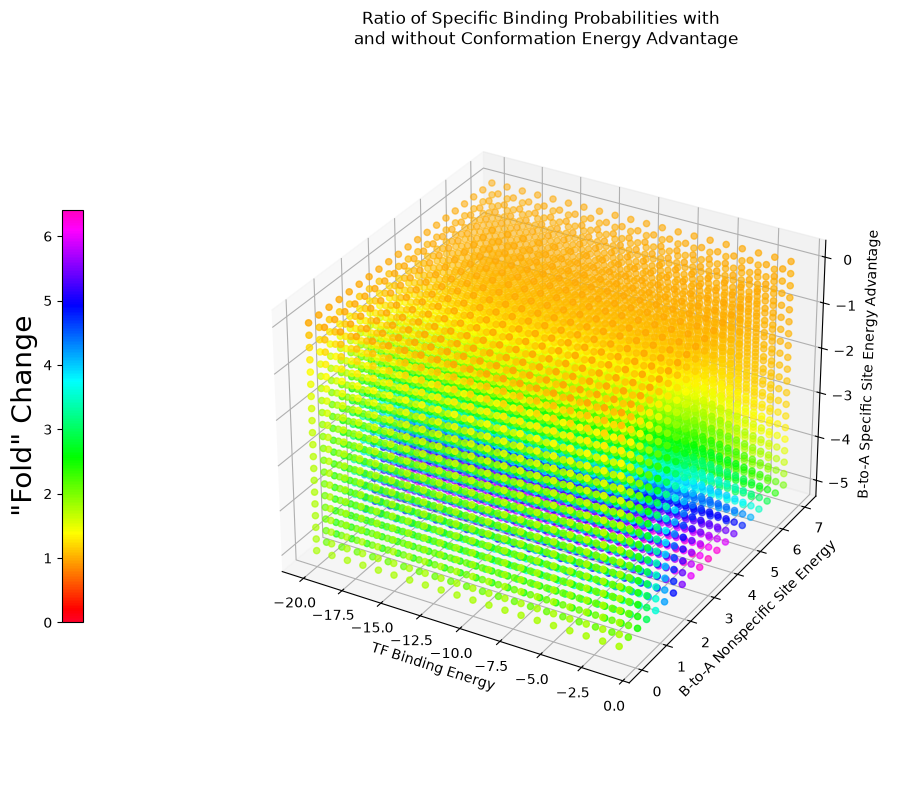

In [6]:
num_vals = 20
zoom_level = 0.85
e_bind_s_c_a_vals = np.linspace(-20,-1,num_vals)
e_con_vals = np.linspace(0,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y,z :spec_site_occupancy(274, 2552, 2400000, 2500, x, y, z) / spec_site_occupancy(274, 2552, 2400000, 2500, x, y, 0)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = np.array(list(map(f, xp_flat, yp_flat, zp_flat))).flatten()
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(1,1,1, projection = '3d')
ax.scatter(xp_flat, yp_flat, zp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_box_aspect(None, zoom = zoom_level)
ax.set_xlabel('TF Binding Energy')
ax.set_ylabel('B-to-A Nonspecific Site Energy')
ax.set_zlabel('B-to-A Specific Site Energy Advantage')
ax.set_title('Ratio of Specific Binding Probabilities with \n and without Conformation Energy Advantage')
cbar = plt.colorbar(mapper, ax = ax, location = 'left', shrink = zoom_level/2)
cbar.set_label('"Fold" Change', fontsize = 20)
fig.tight_layout()

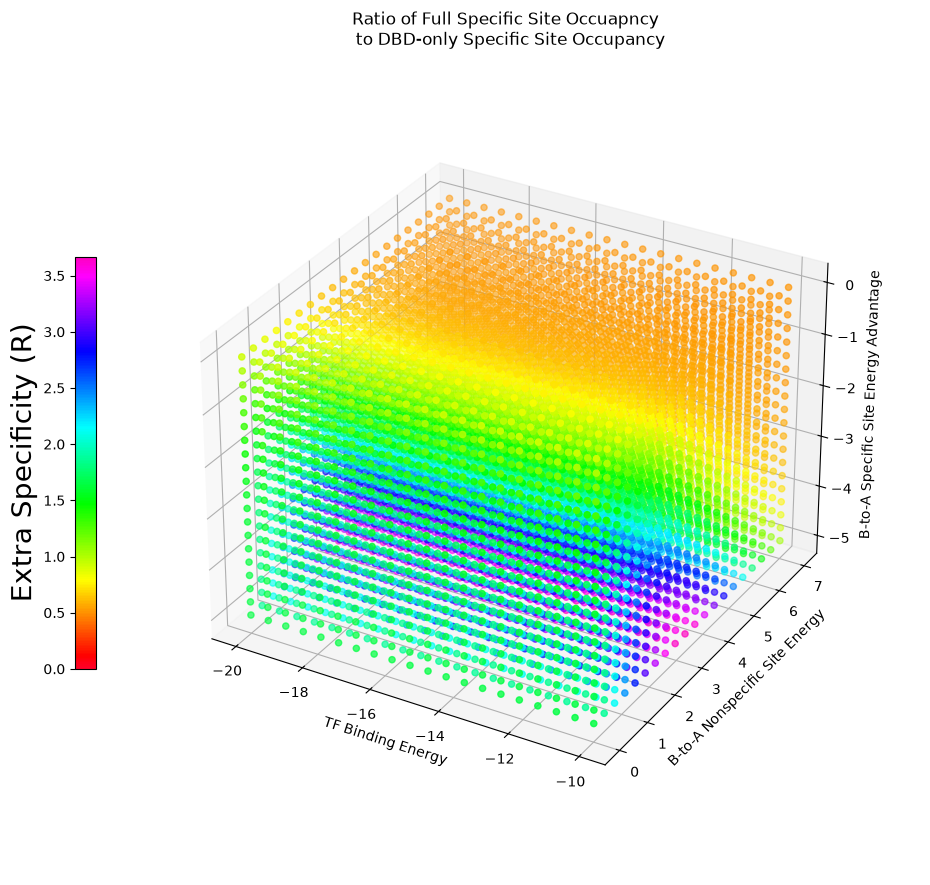

In [20]:
num_vals = 20
zoom_level = 0.85
e_bind_s_c_a_vals = np.linspace(-20,-10,num_vals)
e_con_vals = np.linspace(0,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y,z :spec_site_occupancy(274, 2552, 2400000, 2500, x, y, z) / spec_site_dbd_occupancy(274, 2552, 2400000, 2500, x)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = np.array(list(map(f, xp_flat, yp_flat, zp_flat))).flatten()
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(1,1,1, projection = '3d')
ax.scatter(xp_flat, yp_flat, zp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_box_aspect(None, zoom = zoom_level)
ax.set_xlabel('TF Binding Energy')
ax.set_ylabel('B-to-A Nonspecific Site Energy')
#ax.set_zticks(np.arange(0,6), labels = np.arange(-5,1))
ax.set_zlabel('B-to-A Specific Site Energy Advantage')
#ax.set_zlim(0, min(del_e_con_vals))
ax.set_title('Ratio of Full Specific Site Occuapncy \n to DBD-only Specific Site Occupancy', pad = 0)
cbar = plt.colorbar(mapper, ax = ax, location = 'left', shrink = zoom_level/2, pad = 0)
cbar.set_label('Extra Specificity (R)', fontsize = 20)
fig.tight_layout()
fig.savefig('Comparing Full to DBD in vivo conformational equilibrium model.png')

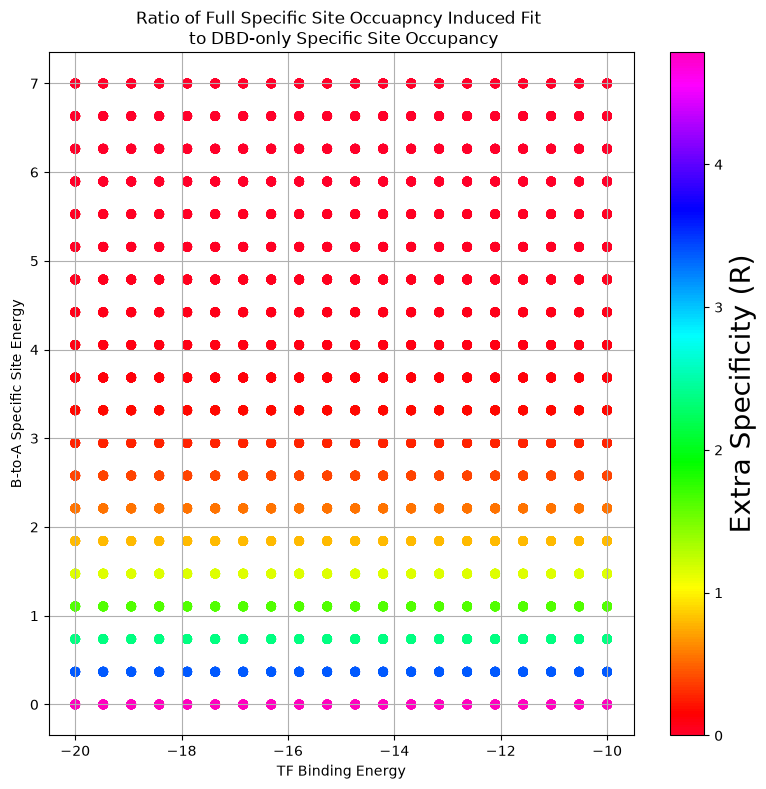

In [8]:
num_vals = 20
zoom_level = 0.85
e_bind_s_c_a_vals = np.linspace(-20,-10,num_vals)
e_con_vals = np.linspace(0,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y :spec_site_occupancy_if(274, 2552, 2400000, 2500, x, y) / spec_site_dbd_occupancy(274, 2552, 2400000, 2500, x)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = np.array(list(map(f, xp_flat, yp_flat))).flatten()
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1)
ax.scatter(xp_flat, yp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_xlabel('TF Binding Energy')
ax.set_ylabel('B-to-A Specific Site Energy')
ax.set_title('Ratio of Full Specific Site Occuapncy Induced Fit \n to DBD-only Specific Site Occupancy')
ax.grid()
cbar = plt.colorbar(mapper, ax = ax)
cbar.set_label('Extra Specificity (R)', fontsize = 20)
fig.tight_layout()
fig.savefig('Comparing Full to DBD in vivo induced fit model.png')

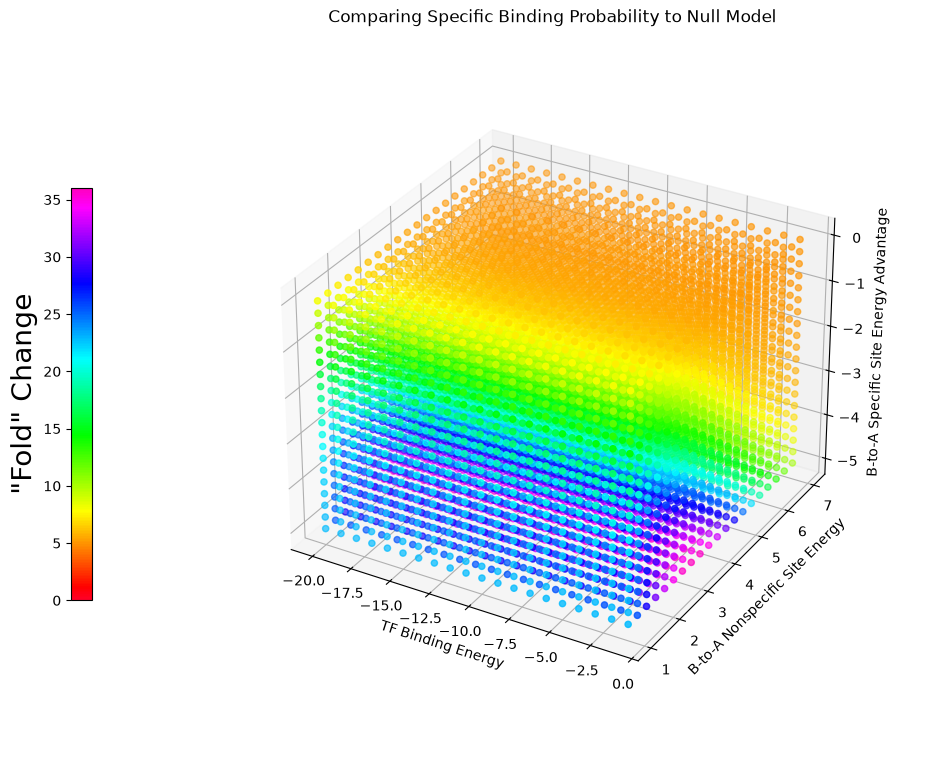

In [9]:
num_vals = 20
zoom_level = 0.85
e_bind_s_c_a_vals = np.linspace(-20,-1,num_vals)
e_con_vals = np.linspace(1,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y,z :spec_site_occupancy(274, 2552, 2400000, 2500, x, y, z) / null_occupancy(274, 2552, 2400000, 2500, x)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = list(map(f, xp_flat, yp_flat, zp_flat))
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(1,1,1, projection = '3d')
ax.scatter(xp_flat, yp_flat, zp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_box_aspect(None, zoom = zoom_level)
ax.set_xlabel('TF Binding Energy')
ax.set_ylabel('B-to-A Nonspecific Site Energy')
#ax.set_ylim(7,0)
ax.set_zlabel('B-to-A Specific Site Energy Advantage')
#ax.set_zlim(0,-5)
ax.set_title('Comparing Specific Binding Probability to Null Model')
cbar = plt.colorbar(mapper, ax = ax, location = 'left', shrink = zoom_level/2)
cbar.set_label('"Fold" Change', fontsize = 20)
fig.tight_layout()

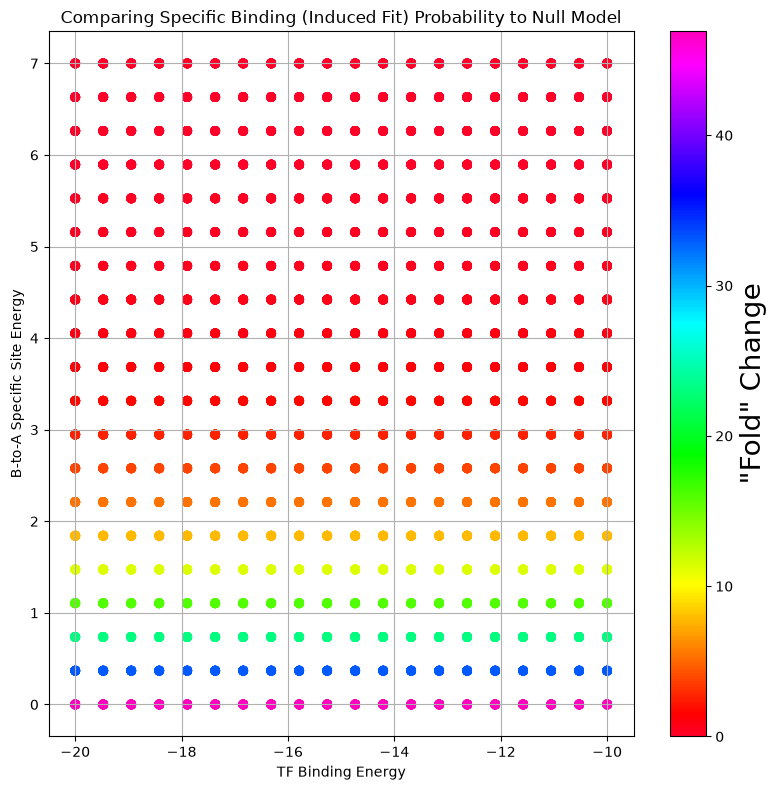

In [10]:
num_vals = 20
e_bind_s_c_a_vals = np.linspace(-20,-10,num_vals)
e_con_vals = np.linspace(0,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y :spec_site_occupancy_if(274, 2552, 2400000, 2500, x, y) / null_occupancy(274, 2552, 2400000, 2500, x)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = list(map(f, xp_flat, yp_flat))
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (8,8))
ax = fig.add_subplot(1,1,1)
ax.scatter(xp_flat, yp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_xlabel('TF Binding Energy')
ax.set_ylabel('B-to-A Specific Site Energy')
ax.set_title('Comparing Specific Binding (Induced Fit) Probability to Null Model')
ax.grid()
cbar = plt.colorbar(mapper, ax = ax)
cbar.set_label('"Fold" Change', fontsize = 20)
fig.tight_layout()

The main thing with induced fit model is that by assuming that the competitor and nonspecific sites can never access A-DNA states due to having high cost of transitioning from B-DNA to A-DNA, extra specificity from the IDR increases mononotonically as the cost of transition decreases. If we plot this in a physiological regime where DNA never favors A-DNA (at most, it costs nothing), the amount of extra specificity is comparable to the typical conformational equilibrium model where A-DNA is accessible to all sites, but specific sites can access it easier.

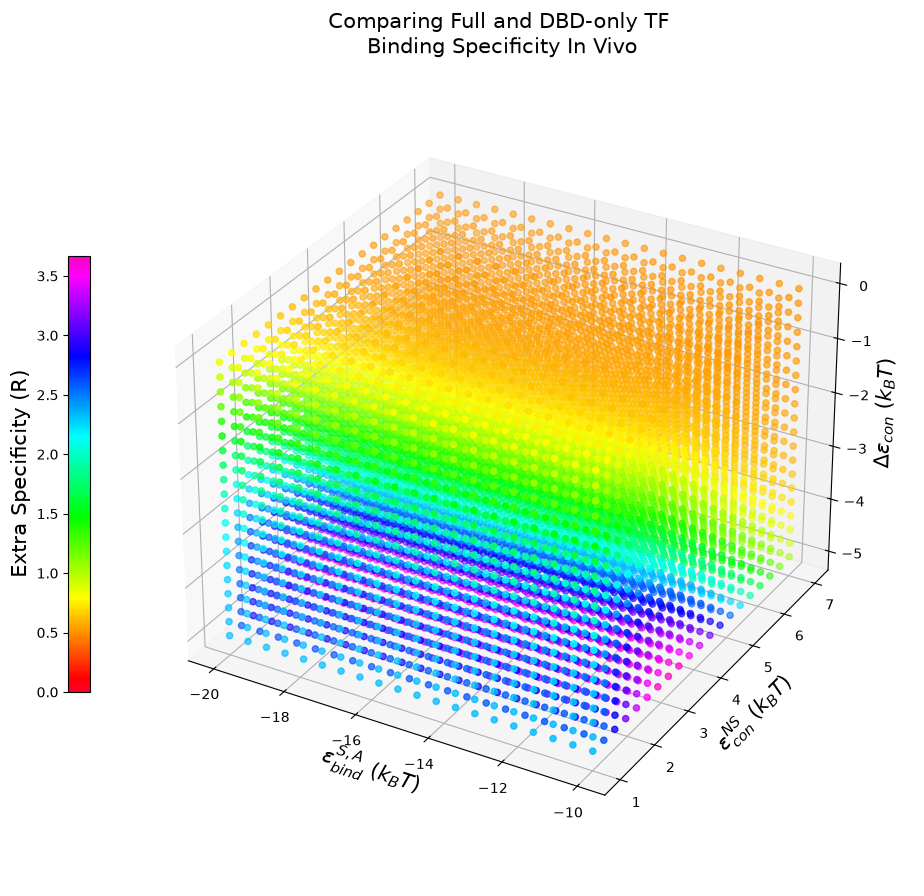

In [11]:
num_vals = 20
zoom_level = 0.90
fs = 15
e_bind_s_c_a_vals = np.linspace(-20,-10,num_vals)
e_con_vals = np.linspace(1,7,num_vals)
del_e_con_vals = np.linspace(-5,0,num_vals)
xp, yp, zp = np.meshgrid(e_bind_s_c_a_vals, e_con_vals, del_e_con_vals)
f = lambda x,y,z :spec_site_occupancy(274, 2552, 2400000, 2500, x, y, z) / spec_site_dbd_occupancy(274, 2552, 2400000, 2500, x)
xp_flat = xp.flatten()
yp_flat = yp.flatten()
zp_flat = zp.flatten()
ratio_vals = np.array(list(map(f, xp_flat, yp_flat, zp_flat))).flatten()
norm = Normalize(vmin = 0, vmax = max(ratio_vals))
mapper = cm.ScalarMappable(norm = norm, cmap = 'gist_rainbow')
fig = plt.figure(figsize = (10,10))
ax = fig.add_subplot(1,1,1, projection = '3d')
ax.scatter(xp_flat, yp_flat, zp_flat, color = mapper.to_rgba(ratio_vals))
ax.set_box_aspect(None, zoom = zoom_level)
ax.set_xlabel(r'$\varepsilon_{bind}^{S,A}$ ($k_BT$)', fontsize = fs)
ax.set_ylabel(r'$\varepsilon_{con}^{NS}$ ($k_BT$)', fontsize = fs)
#ax.set_ylim(7.5,0)
ax.set_zlabel(r'$\Delta \varepsilon_{con}$ ($k_BT$)', fontsize = fs)
#ax.set_zlim(0,-5)
ax.set_title('Comparing Full and DBD-only TF \n Binding Specificity In Vivo ', fontsize = fs)
cbar = plt.colorbar(mapper, ax = ax, location = 'left', shrink = zoom_level/2, pad = 0)
cbar.set_label('Extra Specificity (R)', fontsize = fs)
fig.tight_layout()
fig.savefig('In Vivo MWC Model Full vs DBD Specificity Presentation Style.png')

In wondering why the results of Landman et al. look a lot better, I realized that all of the binding energies they use are relative to the nonspecific binding energy. They set the nonspecific binding energy as the zero point so -17 $k_BT$ in their paper means an energy that is lower than the nonspecific by 17 $k_BT$, not that the actual energy is -17 $k_BT$. This is important since I have approximated that the difference in affinity is about 50 when comparing dissociation constants or 3.9 $k_BT$, much less than what they have in the Landman et al. paper. That could account for why the absolute numbers are so low. Additionally, in the paper, they make the approximation that the repressor fugacity $\lambda_{R} << 1$ is valid when the represssor number is much smaller than the number of available sites (for them, it was about 1000x difference). Since I am in the same regime, it now seems more valid that the fugacity is as low as it is; as they mention in the paper, when there are many more sites than TFs, is essentially the TF concentration normalized to the number of sites, so when there are many more sites than TFs, this normalized concentration is very low.

Update: That is indeed the case. When I derived the results of Landman et al. on my own, I found that if I had a bacterial system where there are 10 copies of the TF, 10 target sites, 5e6 off-target sites, and the specific binding energy was 17.5 $k_BT$ lower than the nonspecific, I could get just under 90% occupancy. This scaled with the binding energy. If I adjust the numbers to represent a simplified scenario of Msn2 (2500 TF copies, 200 target sites,  2.4e6 off-target sites, binding energy difference of just -4 $k_BT$), I get 5% occupancy. This could mean any of the following: 1) I am massively underestimating the difference in binding energy between specific and nonspecific sites 2) eukaryotic transcription factors bind target sites transiently, so even at equilibrium, they tend not to be bound to their target sites. 3) off-target binding could be important for some reason. The second possibility could imply that perhaps the assumption of having all of the TFs bound somewhere on the DNA is not applicable.

In [12]:
fugacity_calc(274, 2552, 2400000, 2500, -20, 5, -5)
#fugacity_calc_v2(201, 1817, 2400000, 2500, -20, 5, -5)

array([1.00534912e-10])

In [13]:
fugacity_calc(274, 2552, 2400000, 2500, -20, 5, -5)

array([1.00534912e-10])

In [14]:
f(-16, 3, 0), f(-16, 3, -2)

(array([0.6048853]), array([1.43634494]))

In [15]:
spec_site_occupancy(274, 2552, 2400000, 2500, -20, 5, -5), spec_site_occupancy(274, 2552, 2400000, 2500, -20, 3, -2)

(array([0.02694763]), array([0.01465345]))

In [16]:
min(ratio_vals), max(ratio_vals)

(np.float64(0.5077250020625799), np.float64(3.6720912647357125))

In [17]:
n_s = np.array([274, 274])
n_c = np.array([2552, 2552])
n_ns = np.array([2400000, 2400000])
T = np.array([2500, 2500])
e_bind_s_c_a = np.array([-17, -10]) 
e_con = np.array([5, 7])
del_e_con = np.array([-3, -5])

# define the specific site binding energies. Competitor sites have the same binding energy, so we will reuse these binding energies
# for those sites as well
e_bind_s_c_b = e_bind_s_c_a + np.log(10)
    
# define binding energies for nonspeicfic sites
e_bind_ns_b = e_bind_s_c_a + np.log(50)
e_bind_ns_a = e_bind_s_c_a + np.log(5)

# define variable represeting exponential MWC energies 
# x for the the binding energies
x_s_c_b = np.exp(-e_bind_s_c_b)
x_s_c_a = np.exp(-e_bind_s_c_a)
x_ns_b = np.exp(-e_bind_ns_b)
x_ns_a = np.exp(-e_bind_ns_a)
# y for conformation energies
y_s = np.exp(-e_con - del_e_con)
y_c_ns = np.exp(-e_con)

# define variables to represent the weight of bound states from the binding energies
alpha_s = x_s_c_b + x_s_c_a * y_s
alpha_c = x_s_c_b + x_s_c_a * y_c_ns
alpha_ns = x_ns_b + x_ns_a * y_c_ns
    
# define the fugacity as a function of the parameters and variables define so far
a = alpha_s * alpha_c * alpha_ns * (n_s + n_c + n_ns - T)
b1 = (1+y_s) * alpha_c * alpha_ns * (n_c + n_ns - T)
b2 = (1+y_c_ns) * alpha_s * alpha_ns * (n_s + n_ns - T)
b3 = (1+y_c_ns) * alpha_s * alpha_c * (n_s + n_c - T)
b = b1 + b2 + b3
c1 = (n_s - T) * alpha_s * (1 + y_c_ns) * (1 + y_c_ns)
c2 = (n_c - T) * alpha_c * (1 + y_s) * (1 + y_c_ns)
c3 = (n_ns - T) * alpha_ns * (1 + y_s) * (1+ y_c_ns)
c = c1 + c2 + c3
d = -T * (1 + y_c_ns) * (1 + y_s) * (1 + y_c_ns) 
if type(a) == np.ndarray:
    coeff_array = np.vstack([d,c,b,a]).T
else:
    coeff_array = np.array([[d,c,b,a]])
fugacity = vec_real_pos_roots(coeff_array)

# define the partition functions for specific, competitor, and nonspecific sites
q_s = 1 + y_s + fugacity * alpha_s
q_c = 1 + y_c_ns + fugacity * alpha_c
q_ns  = 1 + y_c_ns + fugacity * alpha_ns

# define the occupation probabilities of each site
p_s =  (fugacity * alpha_s) / q_s
p_c =  (fugacity * alpha_c) / q_c
p_ns =  (fugacity * alpha_ns) / q_ns

# define the number of TFs bound to each site
bound_s = p_s * n_s
bound_c = p_c * n_c
bound_ns = p_ns * n_ns

# calculate ratio
occupancy = bound_s / n_s

print(p_s)
print(p_c)
print(p_ns)
print(bound_s)
print(bound_c)
print(bound_ns)
print(fugacity)

[0.01002678 0.01053825]
[0.00515387 0.00515358]
[0.00103504 0.00103498]
[2.747338   2.88748145]
[13.15267731 13.15194222]
[2484.09998469 2483.96057633]
[2.02287469e-09 2.33271618e-06]


In [18]:
p_bind = occupancy
motif_freqs = [20, 34, 23, 12, 10, 3]
tot_proms = 0
bound_proms = 0
for idx, motif_freq in enumerate(motif_freqs):
    num_motifs = idx+1
    num_proms = motif_freqs[idx]
    num_bound_proms = num_proms * (1-((1-p_bind)**num_motifs))
    tot_proms += num_proms
    bound_proms += num_bound_proms
print(bound_proms / tot_proms)

[0.02652325 0.02785956]
